# 49. 능동 학습(Human-in-the-loop) 운영 시뮬레이션

**아이디어**: 현장처럼 **시간 순으로 생산 묶음(100샷)마다 10%를 검사**하고, 검사원이 확인한 결과를 즉시 다음 검사 순서·모델에 반영.
미래 라벨은 절대 쓰지 않음 → '라벨이 거의 없는 상태에서 시작해도 운영하면서 나아지나'를 확인 (보고서 4장 운영 시나리오 근거)

| 전략 | 내용 |
|---|---|
| S0 무작위 | 기준선 |
| S1 고정 순위 | 기본 점수 순 (학습 없음) |
| S2 고정 + 주변 확장 | 불량 발견 시 같은 묶음 앞뒤 5샷 먼저 검사 (몰려 나오는 성질 이용) |
| S3 온라인 학습 | 검사 결과(불량 ≥2개부터) + 정상 기준 샷으로 RF 재학습, 기본 점수와 순위 평균, 20%는 탐색 |
| S4 온라인 + 주변 확장 | S3 + S2 |

- 기본 점수: `combo` = 최종 모델 경보 먼저 + std4 흔들림 (38번 규칙) / `final` = 최종 모델 점수
- 모든 전략의 검사 샷 수는 같음 → 찾은 불량 수를 바로 비교
- 실행 시간: 수 분 (온라인 전략은 묶음마다 RF 재학습, 시드 5개)

In [1]:
import pandas as pd
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40); pd.set_option('display.max_rows', 200)
%load_ext autoreload
%autoreload 2
import active_learning as AL
R = AL.run(products=('cn7', 'rg3'), bases=('combo', 'final'), seeds=(0, 1, 2, 3, 4), block=100)

  [cn7] combo · S0 무작위 완료
  [cn7] combo · S1 고정 순위 완료
  [cn7] combo · S2 고정 + 주변 확장 완료
  [cn7] combo · S3 온라인 학습 완료
  [cn7] combo · S4 온라인 + 주변 확장 완료
  [cn7] final · S0 무작위 완료
  [cn7] final · S1 고정 순위 완료
  [cn7] final · S2 고정 + 주변 확장 완료
  [cn7] final · S3 온라인 학습 완료
  [cn7] final · S4 온라인 + 주변 확장 완료
  [rg3] combo · S0 무작위 완료
  [rg3] combo · S1 고정 순위 완료
  [rg3] combo · S2 고정 + 주변 확장 완료
  [rg3] combo · S3 온라인 학습 완료
  [rg3] combo · S4 온라인 + 주변 확장 완료
  [rg3] final · S0 무작위 완료
  [rg3] final · S1 고정 순위 완료
  [rg3] final · S2 고정 + 주변 확장 완료
  [rg3] final · S3 온라인 학습 완료
  [rg3] final · S4 온라인 + 주변 확장 완료


## 전략별 결과 (시드 평균)

In [2]:
display(R['summary'].round(3))

,제품,기본 점수,전략,검사_샷,찾은_불량,범위,전체_불량,가스,가스_전체,미성형,미성형_전체,Precision,Recall,F1
0,cn7,combo,S0 무작위,199,1.4,0~3,15,0.8,11,0.6,4,0.007,0.093,0.013
1,cn7,combo,S1 고정 순위,199,5.0,5~5,15,2.0,11,3.0,4,0.025,0.333,0.047
2,cn7,combo,S2 고정 + 주변 확장,199,8.0,8~8,15,5.0,11,3.0,4,0.040,0.533,0.075
3,cn7,combo,S3 온라인 학습,199,4.6,4~5,15,1.6,11,3.0,4,0.023,0.307,0.043
4,cn7,combo,S4 온라인 + 주변 확장,199,5.8,5~7,15,2.8,11,3.0,4,0.029,0.387,0.054
5,cn7,final,S0 무작위,199,1.4,0~3,15,0.8,11,0.6,4,0.007,0.093,0.013
6,cn7,final,S1 고정 순위,199,3.0,3~3,15,0.0,11,3.0,4,0.015,0.200,0.028
7,cn7,final,S2 고정 + 주변 확장,199,7.0,7~7,15,4.0,11,3.0,4,0.035,0.467,0.065
8,cn7,final,S3 온라인 학습,199,3.2,3~4,15,0.2,11,3.0,4,0.016,0.213,0.030
9,cn7,final,S4 온라인 + 주변 확장,199,6.2,6~7,15,3.2,11,3.0,4,0.031,0.413,0.058


## 누적 발견 곡선

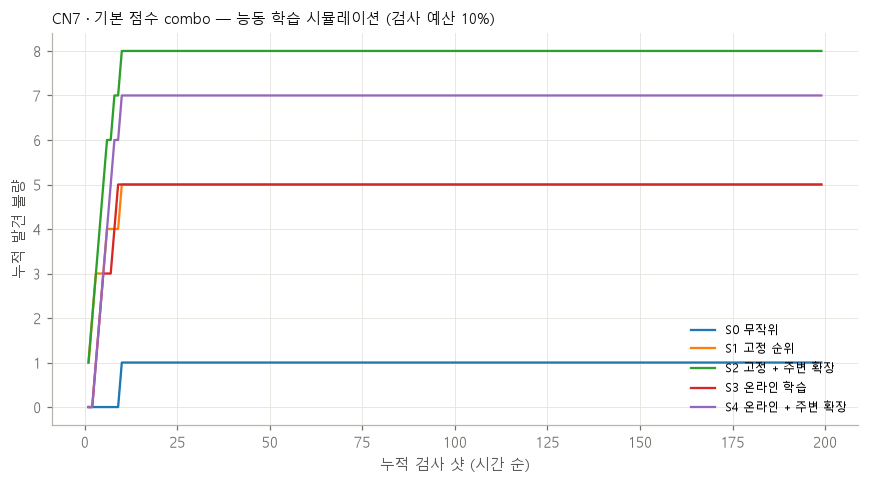

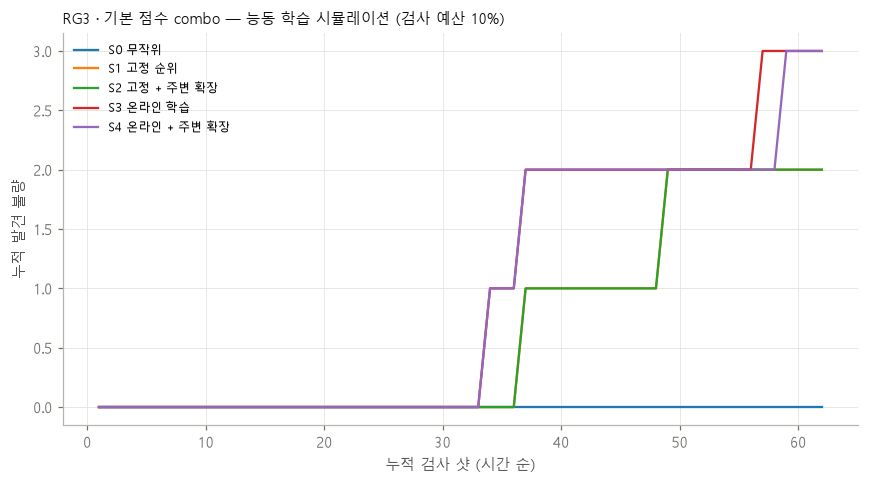

In [3]:
AL.plot_curves(R, 'cn7', 'combo')
AL.plot_curves(R, 'rg3', 'combo')

## 에피소드 — 첫 불량을 찾기까지 검사 샷 수, 그 뒤로 더 찾은 불량

In [4]:
E = R['episodes']
display(E.groupby(['제품', '기본 점수', '전략', 'Run'], sort=False)[['Run 불량', '첫 불량까지 검사 샷', '첫 발견 이후 찾은 불량']].mean().round(1))

Run 불량  첫 불량까지 검사 샷  첫 발견 이후 찾은 불량
제품  기본 점수 전략             Run                                       
cn7 combo S0 무작위         cn7_R1    14.0          5.8            0.4
                         cn7_R6     1.0         25.0            0.0
          S1 고정 순위       cn7_R1    14.0          1.0            4.0
                         cn7_R6     1.0          NaN            0.0
          S2 고정 + 주변 확장  cn7_R1    14.0          1.0            7.0
                         cn7_R6     1.0          NaN            0.0
          S3 온라인 학습      cn7_R1    14.0          2.0            3.6
                         cn7_R6     1.0          NaN            0.0
          S4 온라인 + 주변 확장 cn7_R1    14.0          2.0            4.8
                         cn7_R6     1.0          NaN            0.0
    final S0 무작위         cn7_R1    14.0          5.8            0.4
                         cn7_R6     1.0         25.0            0.0
          S1 고정 순위       cn7_R1    14.0          1.0            2.0
                         cn7_R6     1.0          NaN            0.0
          S2 고정 + 주변 확장  cn7_R1    14.0          1.0            6.0
                         cn7_R6     1.0          NaN            0.0
          S3 온라인 학습      cn7_R1    14.0          2.0            2.2
                         cn7_R6     1.0          NaN            0.0
          S4 온라인 + 주변 확장 cn7_R1    14.0          2.0            5.2
                         cn7_R6     1.0          NaN            0.0
rg3 combo S0 무작위         rg3_R2     5.0          5.8            0.2
                         rg3_R3    10.0          5.7            0.0
                         rg3_R4     4.0          5.0            0.0
                         rg3_R5     6.0          7.0            0.0
          S1 고정 순위       rg3_R2     5.0          NaN            0.0
                         rg3_R3    10.0          NaN            0.0
                         rg3_R4     4.0          1.0            0.0
                         rg3_R5     6.0          5.0            0.0
          S2 고정 + 주변 확장  rg3_R2     5.0          NaN            0.0
                         rg3_R3    10.0          NaN            0.0
                         rg3_R4     4.0          1.0            0.0
                         rg3_R5     6.0          5.0            0.0
          S3 온라인 학습      rg3_R2     5.0          NaN            0.0
                         rg3_R3    10.0         18.0            0.0
                         rg3_R4     4.0          1.0            0.0
                         rg3_R5     6.0          8.4            0.0
          S4 온라인 + 주변 확장 rg3_R2     5.0          NaN            0.0
                         rg3_R3    10.0         18.0            0.0
                         rg3_R4     4.0          1.0            0.0
                         rg3_R5     6.0          7.4            0.2
    final S0 무작위         rg3_R2     5.0          5.8            0.2
                         rg3_R3    10.0          5.7            0.0
                         rg3_R4     4.0          5.0            0.0
                         rg3_R5     6.0          7.0            0.0
          S1 고정 순위       rg3_R2     5.0          NaN            0.0
                         rg3_R3    10.0         15.0            0.0
                         rg3_R4     4.0          3.0            0.0
                         rg3_R5     6.0          NaN            0.0
          S2 고정 + 주변 확장  rg3_R2     5.0          NaN            0.0
                         rg3_R3    10.0         15.0            0.0
                         rg3_R4     4.0          3.0            0.0
                         rg3_R5     6.0          NaN            0.0
          S3 온라인 학습      rg3_R2     5.0          NaN            0.0
                         rg3_R3    10.0         11.0            0.4
                         rg3_R4     4.0          3.2            0.2
                         rg3_R5     6.0         10.7            0.4
          S4 온라인 + 주변 확장 rg3_R2     5.0          NaN            0.0
                     

## 묶음 크기 민감도 (50샷 = 더 자주 검사·학습)

In [5]:
R50 = AL.run(products=('cn7', 'rg3'), bases=('combo',), seeds=(0, 1, 2), block=50, verbose=False)
display(R50['summary'].round(3))

,제품,기본 점수,전략,검사_샷,찾은_불량,범위,전체_불량,가스,가스_전체,미성형,미성형_전체,Precision,Recall,F1
0,cn7,combo,S0 무작위,199,2.333,2~3,15,1.000,11,1.333,4,0.012,0.156,0.022
1,cn7,combo,S1 고정 순위,199,5.000,5~5,15,2.000,11,3.000,4,0.025,0.333,0.047
2,cn7,combo,S2 고정 + 주변 확장,199,6.000,6~6,15,3.000,11,3.000,4,0.030,0.400,0.056
3,cn7,combo,S3 온라인 학습,199,4.667,4~5,15,1.667,11,3.000,4,0.023,0.311,0.044
4,cn7,combo,S4 온라인 + 주변 확장,199,4.667,4~5,15,1.667,11,3.000,4,0.023,0.311,0.044
5,rg3,combo,S0 무작위,62,2.333,1~3,25,1.000,17,1.333,8,0.038,0.093,0.054
6,rg3,combo,S1 고정 순위,62,4.000,4~4,25,2.000,17,2.000,8,0.065,0.160,0.092
7,rg3,combo,S2 고정 + 주변 확장,62,4.000,4~4,25,2.000,17,2.000,8,0.065,0.160,0.092
8,rg3,combo,S3 온라인 학습,62,3.667,2~5,25,2.000,17,1.667,8,0.059,0.147,0.084
9,rg3,combo,S4 온라인 + 주변 확장,62,3.000,2~4,25,2.333,17,0.667,8,0.048,0.120,0.069


## (선택) 학습 효과 검증 — 라벨 원형 이동 시 S3−S1 이득의 우연 분포 (20번, 수 분)

In [6]:
# print(AL.learning_null('cn7', 'combo', n=20))
# print(AL.learning_null('rg3', 'combo', n=20))

## 읽는 법
1. **S2 − S1**: 불량 발견 후 주변 집중 검사의 이득 (학습 없음, 몰림이라는 실제 성질 이용 — 44번 팀원 규칙의 '현장형' 버전)
2. **S3 − S1**: 검사 결과로 학습한 이득. learning_null p < 0.05 여야 변수 학습 덕분이라고 말할 수 있음
3. **첫 불량까지 검사 샷**: 작을수록 에피소드 초기에 발견 → 이후 주변 확장으로 추가 발견
4. 보고서 제안: '경보 → 검사 → 불량 확인 시 주변 확장 + 결과 피드백' 운영 루프의 정량 근거